# AI-Based Satellite Power Simulation

## 4.1 — Introduction

This notebook develops a data-driven satellite electrical power simulation as part of the **Dream in Orbit — An AI That Simulates a Satellite** project.

The simulation integrates the trained Histogram Gradient Boosting models developed in Notebook 03 to predict satellite power approximately 288 seconds (4.8 minutes) ahead.

Historical satellite power measurements will serve as simulation inputs, allowing the system to demonstrate how actual and predicted power values evolve over time.

### Simulation Objectives

1. Load the previously trained AI prediction models.
2. Reuse the processed satellite datasets without repeating preprocessing.
3. Generate time-ordered satellite power predictions.
4. Simulate the progression of satellite power measurements and forecasts.
5. Prepare simulation outputs for interactive visualization.

### Scope

The simulation focuses on satellite electrical power behavior using historical telemetry and machine-learning predictions.

It does not currently model orbital mechanics, spacecraft attitude control, or detailed satellite electrical components.

The simulation will provide a foundation for an interactive demonstration of AI-assisted satellite power forecasting.

## 4.2 — Simulation Environment and Data Loading

### 4.2.1 — Import Libraries and Configure Project Paths

This section initializes the satellite power simulation environment.

The simulation reuses the trained machine-learning models and processed datasets generated in earlier notebooks. Project directories are configured to ensure consistent access to these artifacts without repeating data preprocessing or model training.

In [1]:
# Section 4.2.1 — Import Libraries and Configure Project Paths

from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

# Project directory
project_root = Path.cwd().resolve()

# Existing processed datasets
data_dir = project_root / "data" / "processed"

# Previously trained AI models
model_dir = data_dir / "models"

# Verify required directories
assert data_dir.is_dir(), (
    f"Processed data directory not found: {data_dir}"
)

assert model_dir.is_dir(), (
    f"Trained model directory not found: {model_dir}"
)

# Simulation configuration
FORECAST_HORIZON_SECONDS = 288
SIMULATION_YEAR = "annee1"

print("Satellite Power Simulation Environment")
print("-" * 45)
print(f"Project directory: {project_root}")
print(f"Processed datasets: {data_dir}")
print(f"Trained models: {model_dir}")
print(f"Simulation year: {SIMULATION_YEAR}")
print(f"Forecast horizon: {FORECAST_HORIZON_SECONDS} seconds")

print("\nPASS: Simulation environment configured successfully.")

Satellite Power Simulation Environment
---------------------------------------------
Project directory: C:\Users\DAMISA\Desktop\DAMISA\ECE M2\M2 Sem 1\FABLAB\Dream Orbit\Dream-in-Orbit-an-AI-that-simulates-a-satellite
Processed datasets: C:\Users\DAMISA\Desktop\DAMISA\ECE M2\M2 Sem 1\FABLAB\Dream Orbit\Dream-in-Orbit-an-AI-that-simulates-a-satellite\data\processed
Trained models: C:\Users\DAMISA\Desktop\DAMISA\ECE M2\M2 Sem 1\FABLAB\Dream Orbit\Dream-in-Orbit-an-AI-that-simulates-a-satellite\data\processed\models
Simulation year: annee1
Forecast horizon: 288 seconds

PASS: Simulation environment configured successfully.


 ### 4.2.2 — Load Trained AI Model and Simulation Dataset

This section loads the previously trained Histogram Gradient Boosting model and the processed satellite test dataset for the selected observation year.

The test dataset provides unseen historical satellite measurements for evaluating the behavior of the AI-powered simulation.

The original feature metadata and fitted scaler are also loaded to maintain consistency with the preprocessing configuration established in Notebook 02.

No model retraining, feature engineering, or additional scaling is performed.

In [2]:
# Section 4.2.2 — Load Trained AI Model and Simulation Dataset

# Locate previously saved artifacts
model_path = model_dir / f"{SIMULATION_YEAR}_hgb_model.joblib"
dataset_path = data_dir / f"{SIMULATION_YEAR}_test.npz"
metadata_path = data_dir / "feature_metadata.joblib"
scalers_path = data_dir / "feature_scalers.joblib"

# Verify required files exist
for file_path in (
    model_path,
    dataset_path,
    metadata_path,
    scalers_path
):
    assert file_path.is_file(), f"Missing artifact: {file_path.name}"

# Load the trained AI model
simulation_model = joblib.load(model_path)

# Load existing test data
with np.load(dataset_path) as saved:
    X_simulation = saved["X"]
    y_simulation = saved["y"]

# Load preprocessing metadata and scaler
simulation_metadata = joblib.load(metadata_path)
simulation_scalers = joblib.load(scalers_path)

feature_columns = list(simulation_metadata["feature_columns"])
target_column = simulation_metadata["target_column"]
simulation_scaler = simulation_scalers[SIMULATION_YEAR]

# Verify consistency
assert X_simulation.shape[0] == y_simulation.shape[0]
assert X_simulation.shape[1] == len(feature_columns)
assert simulation_model.n_features_in_ == len(feature_columns)

print("Satellite Simulation Data Loading")
print("-" * 45)
print(f"Observation year: {SIMULATION_YEAR}")
print(f"AI model: {type(simulation_model).__name__}")
print(f"Input dataset shape: {X_simulation.shape}")
print(f"Target dataset shape: {y_simulation.shape}")
print(f"Number of input features: {len(feature_columns)}")
print(f"Prediction target: {target_column}")

print("\nPASS: AI model and simulation data loaded successfully.")

Satellite Simulation Data Loading
---------------------------------------------
Observation year: annee1
AI model: HistGradientBoostingRegressor
Input dataset shape: (273781, 16)
Target dataset shape: (273781,)
Number of input features: 16
Prediction target: target_NPWD2721

PASS: AI model and simulation data loaded successfully.


## 4.3 — Generate Satellite Power Predictions

This section uses the previously trained Histogram Gradient Boosting model to generate future satellite power predictions from a chronological sequence of historical observations.

A subset of 1,000 observations from the test dataset is selected for the initial simulation.

For each observation, the model predicts the satellite power variable `NPWD2721` approximately 288 seconds (4.8 minutes) ahead.

The simulation compares predicted values with the corresponding recorded future power measurements.

The existing trained model and preprocessed features are reused without additional model training or feature engineering.

In [3]:
# Section 4.3 — Generate Satellite Power Predictions

# Number of observations for the initial simulation
SIMULATION_STEPS = 1000

assert SIMULATION_STEPS <= len(X_simulation)

# Select the first 1,000 chronological observations
X_sequence = X_simulation[:SIMULATION_STEPS]
y_actual = y_simulation[:SIMULATION_STEPS]

# Generate predictions using the trained AI model
y_predicted = simulation_model.predict(X_sequence)

# Verify prediction consistency
assert len(y_predicted) == len(y_actual)
assert np.isfinite(y_predicted).all()
assert np.isfinite(y_actual).all()

# Organize simulation results
simulation_df = pd.DataFrame({
    "Simulation_Step": np.arange(1, SIMULATION_STEPS + 1),
    "Actual_Future_Power": y_actual,
    "Predicted_Future_Power": y_predicted
})

# Calculate prediction errors
simulation_df["Prediction_Error"] = (
    simulation_df["Actual_Future_Power"]
    - simulation_df["Predicted_Future_Power"]
)

simulation_df["Absolute_Error"] = (
    simulation_df["Prediction_Error"].abs()
)

print("AI-Based Satellite Power Simulation")
print("-" * 45)
print(f"Observation year: {SIMULATION_YEAR}")
print(f"Simulation observations: {SIMULATION_STEPS}")
print(f"Forecast horizon: {FORECAST_HORIZON_SECONDS} seconds")

print("\nFirst 10 Simulation Observations:")
display(simulation_df.head(10).round(4))

print("\nPASS: Satellite power predictions generated successfully.")

AI-Based Satellite Power Simulation
---------------------------------------------
Observation year: annee1
Simulation observations: 1000
Forecast horizon: 288 seconds

First 10 Simulation Observations:


,Simulation_Step,Actual_Future_Power,Predicted_Future_Power,Prediction_Error,Absolute_Error
0,1,0.0010,0.0073,-0.0063,0.0063
1,2,0.0010,0.0072,-0.0062,0.0062
2,3,0.0009,0.0073,-0.0064,0.0064
3,4,0.0009,0.0079,-0.0070,0.0070
4,5,0.0010,0.0077,-0.0067,0.0067
5,6,0.0010,0.0076,-0.0066,0.0066
6,7,0.0009,0.0077,-0.0068,0.0068
7,8,0.0009,0.0079,-0.0070,0.0070
8,9,0.0009,0.0077,-0.0068,0.0068
9,10,0.0010,0.0078,-0.0069,0.0069



PASS: Satellite power predictions generated successfully.


## 4.4 — Visualization of AI-Based Satellite Power Predictions

This section visualizes the satellite power predictions generated during the simulation.

Actual future power measurements are compared against the AI-predicted values across 1,000 sequential observations.

The visualization helps identify how closely the trained model follows variations in satellite power and highlights periods of overprediction or underprediction.

The horizontal axis represents the observation sequence rather than elapsed time because explicit timestamps were not included in the exported model-ready datasets.

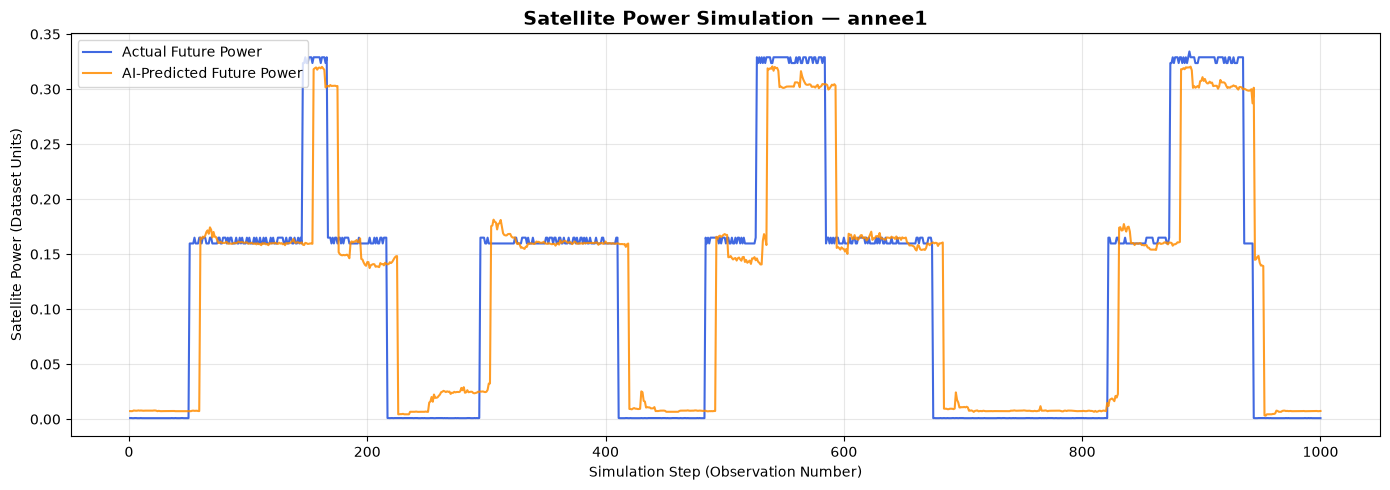

In [4]:
# Section 4.4 — Visualize Actual vs. AI-Predicted Power

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    simulation_df["Simulation_Step"],
    simulation_df["Actual_Future_Power"],
    label="Actual Future Power",
    color="royalblue",
    linewidth=1.5
)

ax.plot(
    simulation_df["Simulation_Step"],
    simulation_df["Predicted_Future_Power"],
    label="AI-Predicted Future Power",
    color="darkorange",
    linewidth=1.5,
    alpha=0.85
)

ax.set_title(
    f"Satellite Power Simulation — {SIMULATION_YEAR}",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Simulation Step (Observation Number)")
ax.set_ylabel("Satellite Power (Dataset Units)")

ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4.5 — Interactive Satellite Power Simulation

This section introduces an interactive replay of the satellite power prediction results.

A slider allows users to navigate through historical observations and inspect the actual and AI-predicted future power values.

The visualization uses the predictions already generated in Section 4.3, without repeating model inference or preprocessing.

The simulation represents a sequential replay of historical telemetry rather than a real-time satellite connection.

In [5]:
# Section 4.5 — Interactive Satellite Power Simulation

from ipywidgets import interact, IntSlider

def display_simulation(step):

    # Select observations up to the current simulation step
    current_data = simulation_df.iloc[:step]

    current = current_data.iloc[-1]

    fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(
        current_data["Simulation_Step"],
        current_data["Actual_Future_Power"],
        label="Actual Future Power",
        color="royalblue",
        linewidth=1.5
    )

    ax.plot(
        current_data["Simulation_Step"],
        current_data["Predicted_Future_Power"],
        label="AI-Predicted Future Power",
        color="darkorange",
        linewidth=1.5
    )

    ax.scatter(
        current["Simulation_Step"],
        current["Predicted_Future_Power"],
        color="red",
        s=60,
        zorder=5
    )

    ax.set_xlim(1, SIMULATION_STEPS)

    ax.set_ylim(
        simulation_df[
            ["Actual_Future_Power", "Predicted_Future_Power"]
        ].min().min() - 0.02,
        simulation_df[
            ["Actual_Future_Power", "Predicted_Future_Power"]
        ].max().max() + 0.02
    )

    ax.set_title(
        f"AI Satellite Power Simulation — Step {step}"
    )

    ax.set_xlabel("Simulation Step (Observation Number)")
    ax.set_ylabel("Satellite Power (Dataset Units)")
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print(f"Simulation step: {step}")
    print(f"Actual future power: {current['Actual_Future_Power']:.4f}")
    print(f"AI-predicted power: {current['Predicted_Future_Power']:.4f}")
    print(f"Absolute prediction error: {current['Absolute_Error']:.4f}")


interact(
    display_simulation,
    step=IntSlider(
        value=100,
        min=1,
        max=SIMULATION_STEPS,
        step=1,
        description="Step:",
        continuous_update=False
    )
)

interactive(children=(IntSlider(value=100, continuous_update=False, description='Step:', max=1000, min=1), Out…

<function __main__.display_simulation(step)>

In [6]:
# Section 4.6 — Satellite Power Operating-State Indicators

# Derive descriptive thresholds from existing predictions
low_threshold, high_threshold = np.quantile(
    simulation_df["Predicted_Future_Power"],
    [0.33, 0.67]
)

def classify_power_level(power):
    if power < low_threshold:
        return "LOW"
    elif power < high_threshold:
        return "MEDIUM"
    return "HIGH"

# Classify the existing simulation predictions
simulation_df["Power_Level"] = (
    simulation_df["Predicted_Future_Power"]
    .apply(classify_power_level)
)

# Summarize the distribution
power_level_summary = (
    simulation_df["Power_Level"]
    .value_counts()
    .reindex(["LOW", "MEDIUM", "HIGH"], fill_value=0)
)

print("Satellite Power-Level Classification")
print("-" * 45)
print(f"Low/medium threshold: {low_threshold:.4f}")
print(f"Medium/high threshold: {high_threshold:.4f}")

print("\nPower-level distribution:")
display(power_level_summary.to_frame("Observations"))

print("\nPASS: Power-level indicators generated successfully.")

Satellite Power-Level Classification
---------------------------------------------
Low/medium threshold: 0.0109
Medium/high threshold: 0.1601

Power-level distribution:


,Observations
Power_Level,
LOW,330
MEDIUM,340
HIGH,330



PASS: Power-level indicators generated successfully.


## 4.7 — Interactive Satellite Power-Level Monitoring

This section extends the existing interactive satellite power simulation by displaying the AI-predicted power level at each observation.

The simulation combines the predicted future power, actual future power, absolute prediction error, and relative power-level classification.

Power levels are derived from the distribution-based thresholds established in Section 4.6. They provide descriptive monitoring information rather than validated spacecraft operating or safety states.

In [7]:
# Section 4.7 — Interactive Satellite Power-Level Monitoring

from ipywidgets import interact, IntSlider

def display_power_monitor(step):
    # Retrieve the selected simulation observation
    observation = simulation_df.iloc[step - 1]

    actual = observation["Actual_Future_Power"]
    predicted = observation["Predicted_Future_Power"]
    error = observation["Absolute_Error"]
    level = observation["Power_Level"]

    # Display monitoring information
    print("AI Satellite Power Monitoring")
    print("-" * 40)
    print(f"Simulation step: {step}")
    print(f"Forecast horizon: {FORECAST_HORIZON_SECONDS} seconds")
    print(f"Actual future power: {actual:.4f}")
    print(f"AI-predicted future power: {predicted:.4f}")
    print(f"Absolute prediction error: {error:.4f}")
    print(f"Predicted power level: {level}")

    # Display a descriptive indicator
    level_icons = {
        "LOW": "🔵",
        "MEDIUM": "🟡",
        "HIGH": "🟢"
    }

    print(f"\nPower-level indicator: {level_icons[level]} {level}")


interact(
    display_power_monitor,
    step=IntSlider(
        value=100,
        min=1,
        max=len(simulation_df),
        step=1,
        description="Step:",
        continuous_update=False
    )
)

interactive(children=(IntSlider(value=100, continuous_update=False, description='Step:', max=1000, min=1), Out…

<function __main__.display_power_monitor(step)>

## 4.8 — Satellite Simulation Performance Evaluation

This section evaluates the predictive performance of the AI-powered satellite simulation using the generated simulation observations.

Three regression metrics are considered:

- **Mean Absolute Error (MAE):** Measures the average magnitude of prediction errors.
- **Root Mean Squared Error (RMSE):** Gives greater weight to larger prediction errors.
- **Coefficient of Determination (R²):** Measures how well the model explains variations in future satellite power.

These metrics provide a quantitative assessment of the simulation's predictive accuracy.

In [8]:
# Section 4.8 — Satellite Simulation Performance Evaluation

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Reuse the simulation results generated in Section 4.3
actual_power = simulation_df["Actual_Future_Power"]
predicted_power = simulation_df["Predicted_Future_Power"]

# Calculate simulation performance metrics
simulation_mae = mean_absolute_error(actual_power, predicted_power)

simulation_rmse = np.sqrt(
    mean_squared_error(actual_power, predicted_power)
)

simulation_r2 = r2_score(actual_power, predicted_power)

# Organize results
simulation_metrics_df = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "Coefficient of Determination (R²)"
    ],
    "Value": [
        simulation_mae,
        simulation_rmse,
        simulation_r2
    ]
})

print("AI Satellite Power Simulation — Performance Evaluation")
print("-" * 55)
print(f"Observation year: {SIMULATION_YEAR}")
print(f"Simulation observations: {len(simulation_df):,}")
print(f"Forecast horizon: {FORECAST_HORIZON_SECONDS} seconds")

display(simulation_metrics_df.round(4))

print("\nPASS: Simulation performance evaluated successfully.")

AI Satellite Power Simulation — Performance Evaluation
-------------------------------------------------------
Observation year: annee1
Simulation observations: 1,000
Forecast horizon: 288 seconds


,Metric,Value
0,Mean Absolute Error (MAE),0.0269
1,Root Mean Squared Error (RMSE),0.0555
2,Coefficient of Determination (R²),0.7557



PASS: Simulation performance evaluated successfully.


### 4.8.1 — Interpretation of Simulation Performance

The AI-powered satellite simulation was evaluated using 1,000 observations from the annee1 test dataset, with a forecasting horizon of 288 seconds (approximately 4.8 minutes).

The simulation achieved a Mean Absolute Error (MAE) of 0.0269, a Root Mean Squared Error (RMSE) of 0.0555, and a coefficient of determination (R²) of 0.7557.

The R² value indicates that the model explains approximately 75.57% of the variation in future satellite power within the selected simulation segment.

The difference between MAE and RMSE suggests that some observations contain relatively large prediction errors, potentially associated with rapid changes in satellite power.

Overall, the results demonstrate the feasibility of using a machine learning model to forecast satellite power from historical telemetry observations. However, the simulation represents a retrospective evaluation using recorded data rather than a live spacecraft simulation.

## 4.9 — Simulation Summary and Limitations

### 4.9.1 — Simulation Summary

This notebook developed an AI-powered satellite power monitoring simulation using the trained Histogram Gradient Boosting regression model from Notebook 03.

The simulation demonstrates the following capabilities:

1. **Satellite Power Forecasting:** Predicts the future value of satellite power variable NPWD2721 approximately 288 seconds (4.8 minutes) ahead.

2. **AI-Based Monitoring:** Compares predicted future satellite power against actual recorded observations.

3. **Interactive Visualization:** Allows users to explore satellite power predictions at different simulation steps.

4. **Power-Level Classification:** Categorizes predicted satellite power into LOW, MEDIUM, and HIGH levels using distribution-based thresholds.

5. **Performance Evaluation:** Evaluates the predictive accuracy of the simulation using MAE, RMSE, and R².

### 4.9.2 — Simulation Limitations

Despite the successful implementation, several limitations should be acknowledged:

- **Historical Data:** The simulation uses recorded satellite telemetry rather than live satellite measurements.
- **Prediction Scope:** The AI predicts one selected satellite power variable rather than the complete spacecraft electrical power system.
- **Forecast Horizon:** Predictions are limited to approximately 4.8 minutes ahead.
- **Power-Level Indicators:** LOW, MEDIUM, and HIGH represent relative statistical categories, not validated spacecraft operating or safety thresholds.
- **Prediction Errors:** Sudden changes in satellite power may produce larger forecasting errors.
- **Physical Simulation:** The system does not currently model satellite orbital dynamics, battery state of charge, solar panel generation, or spacecraft power consumption using physical equations.

### 4.9.3 — Future Improvements

Potential improvements include:

1. Integrating additional satellite telemetry variables.
2. Developing a live or continuously updated telemetry interface.
3. Incorporating orbital dynamics and satellite energy-balance models.
4. Investigating alternative machine learning architectures.
5. Developing an integrated satellite monitoring dashboard.

### 4.9.4 — Conclusion

The project demonstrates how machine learning can be integrated with satellite telemetry data to predict and monitor future satellite power behavior.

The simulation achieved an R² of 0.7557 on the selected 1,000-observation test segment, demonstrating useful predictive capability while highlighting opportunities for improvement.

The resulting system provides a foundation for developing more advanced AI-assisted satellite power monitoring and simulation applications.